# Bioactivity prediction using Tox21 Data

- 8,041 chemicals & 12 assay endpoints
- "1" means active, "0" means inactive


# [1] Setup

In [28]:
# Windows / VS Code Conda DLL path workaround
import os
import sys
from pathlib import Path

if sys.platform == "win32":
    dll_dir = Path(sys.prefix) / "Library" / "bin"

    if dll_dir.is_dir():
        os.environ["PATH"] = (str(dll_dir) + os.pathsep + os.environ["PATH"])

In [29]:
import random
import numpy as np

# Reproducibility: use SEED when splitting data and configuring models.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# [2] Data Loading & Exploration

# SDF file exploration

SMILES of the molecule: C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N)cc3nc2c1.[Cl-]
Properties of the molecule:
Formula : C27H25ClN6
FW : 468.9806 (35.4535+224.2805+209.2465)
DSSTox_CID : 25848
SR-HSE : 0


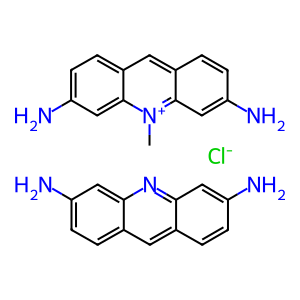

In [30]:
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Draw

# Locate project root
cwd = Path.cwd()
project_root = cwd if (cwd / "pyproject.toml").is_file() else cwd.parent

sdf_path = project_root / "data" / "raw" / "tox21_10k_data_all.sdf"

# Inspect the first molecule
supplier = Chem.SDMolSupplier(str(sdf_path))
mol = supplier[0]

print(f"SMILES of the molecule: {Chem.MolToSmiles(mol)}")

print("Properties of the molecule:")
for prop in mol.GetPropNames():
    print(prop, ":", mol.GetProp(prop))

Draw.MolToImage(mol)


# Identify and consolidate duplicate compounds

In [31]:
from tox21_ml.data import load_sdf

# Load SDF using the data module
df = load_sdf(sdf_path)

display(df.head())


[18:42:07] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[18:42:07] ERROR: Could not sanitize molecule ending on line 21572
[18:42:07] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[18:42:08] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[18:42:08] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[18:42:08] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[18:42:08] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[18:42:09] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[18:42:09] ERROR: Could not sanitize molecule ending on line 446665
[18:42:09] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[18:42:10] Explicit valence for atom # 1 Cl, 1, is greater than permitted
[18:42:10] ERROR: Could not sanitize molecule ending on l

,idx,canonical_smiles,status,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,0,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,ok,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,ok,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,ok,C47H83NO17,934.1584 (916.1205+18.0379),28909,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,ok,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,ok,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
df[df["status"] != "ok"]

,idx,canonical_smiles,status,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
281,281,NaN,parse_failed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5588,5588,NaN,parse_failed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7626,7626,NaN,parse_failed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
# Diagnostic only: count complete duplicates
df_ok = df[df["status"] == "ok"].copy()
print(f"Original molecules: {len(df)} -> Molecules with normal SMILES: {len(df_ok)}")

n_complete_duplicates = df_ok.drop(columns=["idx"]).duplicated().sum()

print("Complete duplicates:", n_complete_duplicates)

print("Duplicate SMILES:", df_ok.duplicated(subset="canonical_smiles").sum())

Original molecules: 11764 -> Molecules with normal SMILES: 11761
Complete duplicates: 281
Duplicate SMILES: 3720


- Complete duplicates: 281 identified during exploration. Duplicate SMILES are consolidated in the subsequent grouping step.
- Duplicates with the same SMILES: For the same endpoints, take activity values as below.
  - NaN + NaN → NaN
  - NaN + 0 → 0 / NaN + 1 → 1
  - 0 + 1 → **NaN** (conflict!)

In [34]:
dup_smiles_rows = df[df["canonical_smiles"].duplicated(keep=False)].sort_values("canonical_smiles")
dup_smiles_rows.head(20)

,idx,canonical_smiles,status,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
687,687,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,ok,C17H22BrNO4,384.2649 (303.3529+80.9119),25419,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4455,4455,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,ok,C17H22BrNO4,384.2649 (303.3529+80.9119),25419,NaN,0,NaN,0,0,0,0,NaN,0,0,0,0
5647,5647,Br.CN1[C@@H]2CC[C@H]1C[C@@H](OC(=O)C(O)c1ccccc...,ok,C16H22BrNO3,356.2548 (275.3428+80.9119),25099,NaN,1,NaN,0,0,0,0,0,0,0,0,0
1011,1011,Br.CN1[C@@H]2CC[C@H]1C[C@@H](OC(=O)C(O)c1ccccc...,ok,C16H22BrNO3,356.2548 (275.3428+80.9119),25099,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5648,5648,Br.CN1[C@@H]2CC[C@H]1C[C@@H](OC(=O)C(O)c1ccccc...,ok,C16H22BrNO3,356.2548 (275.3428+80.9119),25099,NaN,0,NaN,0,0,0,0,0,0,0,0,0
5651,5651,Br.CN1[C@@H]2C[C@@H](OC(=O)[C@H](CO)c3ccccc3)C...,ok,C17H22BrNO4,384.2649 (303.3529+80.9119),12029,NaN,0,NaN,0,0,0,0,0,0,0,0,0
10210,10210,Br.CN1[C@@H]2C[C@@H](OC(=O)[C@H](CO)c3ccccc3)C...,ok,C17H22BrNO4,384.2649 (303.3529+80.9119),12029,0,0,0,0,0,0,0,0,0,0,0,0
1012,1012,Br.CN1[C@@H]2C[C@@H](OC(=O)[C@H](CO)c3ccccc3)C...,ok,C17H22BrNO4,384.2649 (303.3529+80.9119),12029,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5649,5649,Br.CN1[C@@H]2C[C@@H](OC(=O)[C@H](CO)c3ccccc3)C...,ok,C17H28BrNO7,438.3107 (80.9119+18.0153+18.0153+18.0153+303....,1258,NaN,0,NaN,0,0,0,0,1,0,0,0,0
9472,9472,Br.CN1[C@@H]2C[C@@H](OC(=O)[C@H](CO)c3ccccc3)C...,ok,C17H28BrNO7,438.3107 (80.9119+18.0153+18.0153+18.0153+303....,1258,0,0,0,0,0,0,0,0,0,0,0,0


In [35]:
df_ok.columns[6:]

Index(['SR-HSE', 'NR-AR', 'SR-ARE', 'NR-Aromatase', 'NR-ER-LBD', 'NR-AhR',
       'SR-MMP', 'NR-ER', 'NR-PPAR-gamma', 'SR-p53', 'SR-ATAD5', 'NR-AR-LBD'],
      dtype='str')

In [36]:
import pandas as pd
from tox21_ml.data import group_and_filter_tox21

df_grouped, df_filtered, endpoint_column = (
    group_and_filter_tox21(df_ok)
)

print(df_ok.shape, "→", df_grouped.shape)

(11761, 18) → (8041, 17)


# Data exploration

In [37]:
# Data overview
overview = pd.DataFrame({
    "dtype": df_filtered.dtypes.astype(str),
    "non_null_count": df_filtered.notna().sum(),
    "count_0": (df_filtered == 0).sum(),
    "count_1": (df_filtered == 1).sum()
})

overview["count_sum"] = (
    overview["count_0"] + overview["count_1"]
)

overview["non_null_count = count_sum ?"] = (
    overview["non_null_count"] == overview["count_sum"]
)

# Display as plain text
print(
    overview.sort_values(
        by="non_null_count",
        ascending=False
    ).to_string()
)

                    dtype  non_null_count  count_0  count_1  count_sum  non_null_count = count_sum ?
idx                 int64            8041        1        1          2                         False
canonical_smiles      str            8041        0        0          0                         False
Formula               str            8041        0        0          0                         False
FW                    str            8041        0        0          0                         False
DSSTox_CID            str            8041        0        0          0                         False
NR-AR             float64            7417     7156      261       7417                          True
SR-ATAD5          float64            7230     6987      243       7230                          True
NR-ER-LBD         float64            7082     6779      303       7082                          True
SR-p53            float64            6909     6498      411       6909                     

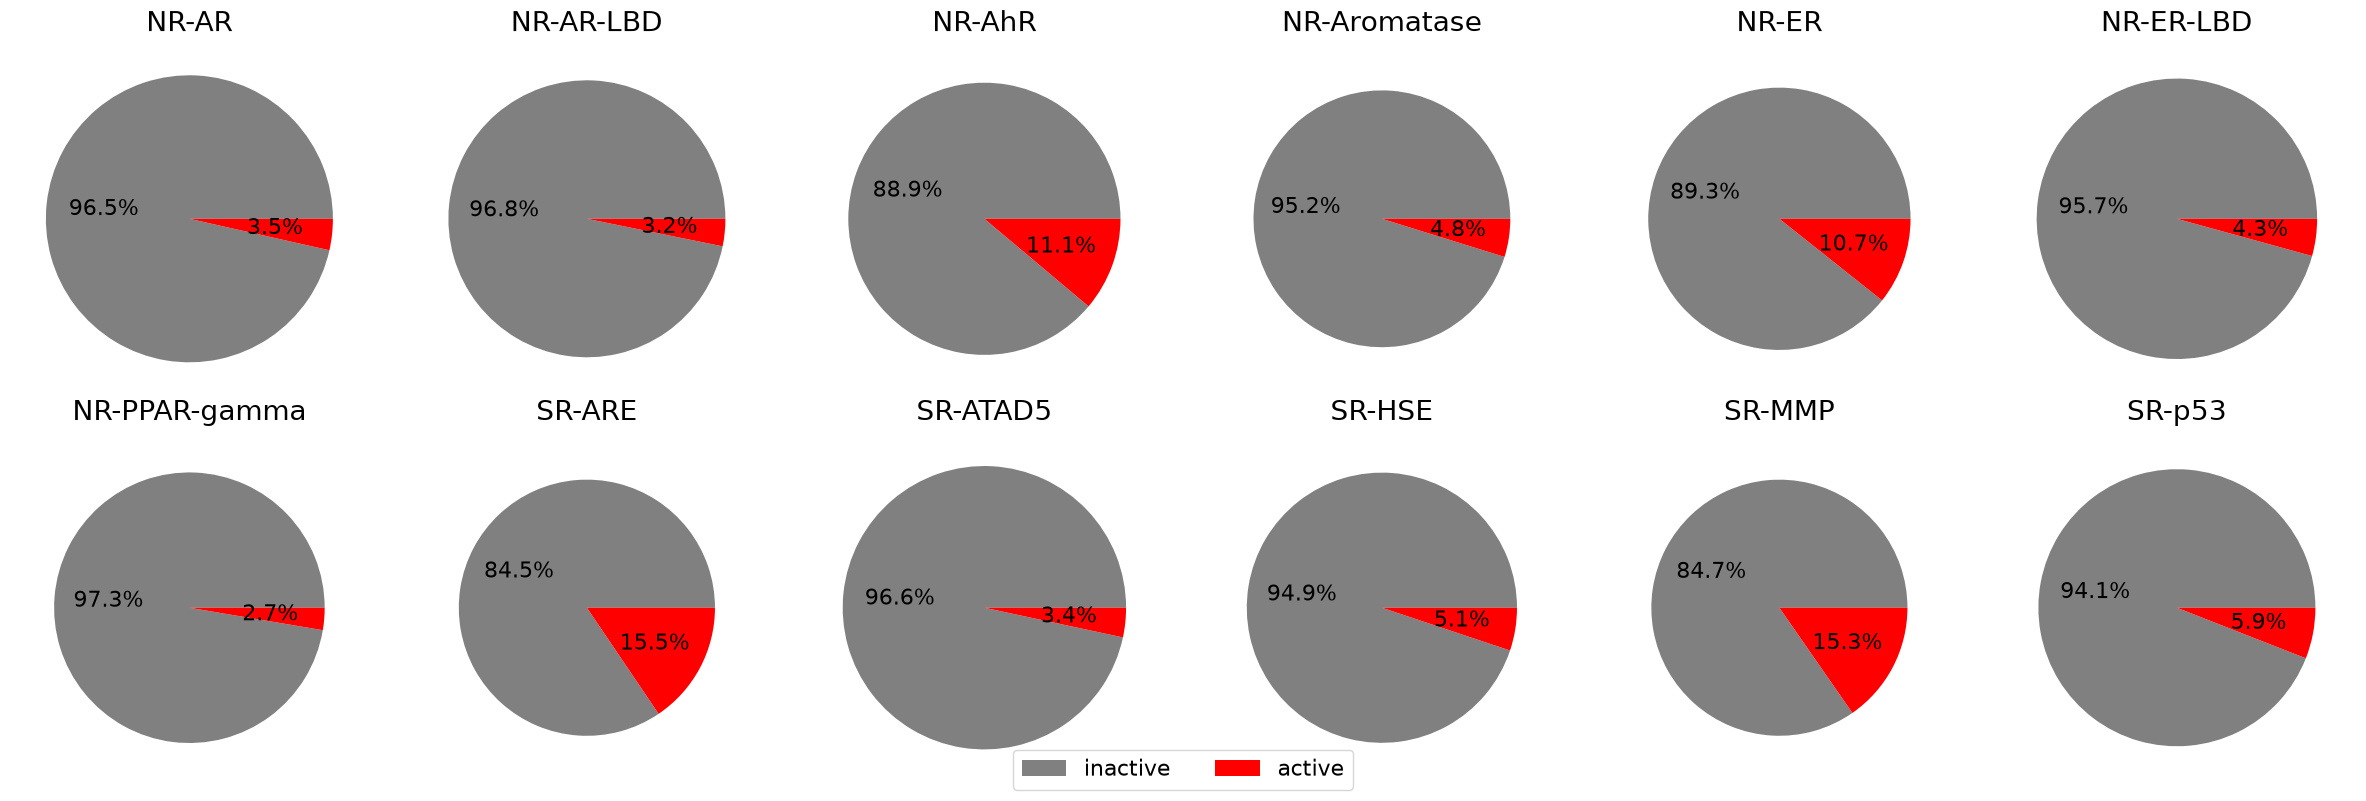

In [38]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

overview_for_plot = overview.loc[list(endpoint_column)].sort_index()

# subplot structure
ncols = 6
nrows = 2

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
axes = axes.flatten()

# radius 정규화용
max_sum = overview_for_plot["count_sum"].max()

for ax, (idx, row) in zip(axes, overview_for_plot.iterrows()):
    values = [row["count_0"], row["count_1"]]

    # count_sum에 비례하도록 반지름 설정
    # 너무 차이가 크면 작은 파이가 너무 안 보이므로 sqrt 추천
    radius = (row["count_sum"] / max_sum) ** 0.5

    ax.pie(
        values,
        colors = ["gray", "red"],
        autopct="%1.1f%%",
        radius=radius,
        textprops={'fontsize': 16}
    )
    ax.set_title(str(idx), fontsize=20)

# Create box for legend
legend_elements = [
    Patch(facecolor='gray', label='inactive'),
    Patch(facecolor='red', label='active')
]

# Add legend
fig.legend(
    handles=legend_elements,
    loc='lower center',
    fontsize=16,
    ncol=2
)

plt.tight_layout()
plt.show()

In [39]:
df_filtered.shape

(8041, 17)

In [53]:
# chemical 기준 - NaN data coverage
null_per_row = df_filtered.isna().sum(axis=1)
null_per_row = (df_filtered[list(endpoint_column)].isna().sum(axis=1))
null_per_row = null_per_row.value_counts().sort_index()
null_per_row

0     2899
1     1607
2     1213
3      695
4      439
5      282
6      184
7      117
8       68
9       53
10     385
11      99
Name: count, dtype: int64

In [41]:
for i in range(0,12):
  covered_num = null_per_row.loc[0:i].sum()
  entire_num = df_filtered.shape[0]
  print(f"When we include chemicals with {i} nulls, we can cover {covered_num} out of {entire_num} tested compounds, which is {covered_num/entire_num*100:.1f}% of entire dataset.")


When we include chemicals with 0 nulls, we can cover 2899 out of 8041 tested compounds, which is 36.1% of entire dataset.
When we include chemicals with 1 nulls, we can cover 4506 out of 8041 tested compounds, which is 56.0% of entire dataset.
When we include chemicals with 2 nulls, we can cover 5719 out of 8041 tested compounds, which is 71.1% of entire dataset.
When we include chemicals with 3 nulls, we can cover 6414 out of 8041 tested compounds, which is 79.8% of entire dataset.
When we include chemicals with 4 nulls, we can cover 6853 out of 8041 tested compounds, which is 85.2% of entire dataset.
When we include chemicals with 5 nulls, we can cover 7135 out of 8041 tested compounds, which is 88.7% of entire dataset.
When we include chemicals with 6 nulls, we can cover 7319 out of 8041 tested compounds, which is 91.0% of entire dataset.
When we include chemicals with 7 nulls, we can cover 7436 out of 8041 tested compounds, which is 92.5% of entire dataset.
When we include chemical

# [3] Molecular Feature Engineering

# 1-1. Create Morgan fingerprint

In [42]:
from tox21_ml.features import (
    build_morgan_fp_to_df,
    add_basic_descriptors_to_df,
    build_feature_matrix,
)

In [43]:
df_filtered.head(3)

,idx,canonical_smiles,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,687,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,C17H22BrNO4,384.2649 (303.3529+80.9119),25419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0
1,5652,Br.CC(N)Cc1ccc(O)cc1,C9H14BrNO,232.1176 (80.9119+151.2056),25961,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3557,Br.CCCCCCCCN1C=CN(C)C1,C12H25BrN2,277.2443 (196.3324+80.9119),29288,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,NaN,0.0,0.0


In [44]:
df_w_fp = build_morgan_fp_to_df(df_filtered, smiles_col="canonical_smiles")
df_w_fp.head(3)

[18:42:24] WARNING: not removing hydrogen atom without neighbors


,idx,canonical_smiles,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD,morgan_fp,is_valid
0,687,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,C17H22BrNO4,384.2649 (303.3529+80.9119),25419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True
1,5652,Br.CC(N)Cc1ccc(O)cc1,C9H14BrNO,232.1176 (80.9119+151.2056),25961,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True
2,3557,Br.CCCCCCCCN1C=CN(C)C1,C12H25BrN2,277.2443 (196.3324+80.9119),29288,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,NaN,0.0,0.0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, ...",True


In [45]:
print(f"Original df (df_filtered): {len(df_filtered)} molecules \nValid SMILES: {df_w_fp['is_valid'].sum()} molecules -> successfully converted to morgan fingerprint in df_w_fp")
print(df_w_fp["morgan_fp"][0].shape)
print(df_w_fp["morgan_fp"][0]) # 0번째 row fingerprint

Original df (df_filtered): 8041 molecules 
Valid SMILES: 8041 molecules -> successfully converted to morgan fingerprint in df_w_fp
(2048,)
[0 1 0 ... 0 0 0]


# 1-2. calculate RDKit descritors

In [46]:
df_w_fp.head(3)

,idx,canonical_smiles,Formula,FW,DSSTox_CID,SR-HSE,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD,morgan_fp,is_valid
0,687,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,C17H22BrNO4,384.2649 (303.3529+80.9119),25419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True
1,5652,Br.CC(N)Cc1ccc(O)cc1,C9H14BrNO,232.1176 (80.9119+151.2056),25961,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True
2,3557,Br.CCCCCCCCN1C=CN(C)C1,C12H25BrN2,277.2443 (196.3324+80.9119),29288,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,0.0,NaN,0.0,0.0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, ...",True


In [47]:
df_w_fp_desc = add_basic_descriptors_to_df(df_w_fp)

[18:42:28] WARNING: not removing hydrogen atom without neighbors


In [48]:
print(df_w_fp_desc.head(3))
print(
    f"Among {len(df_w_fp_desc)} molecules, "
    f"we got all valid descriptors from "
    f"{df_w_fp_desc['desc_valid'].sum()} molecules."
)

    idx                         canonical_smiles      Formula  \
0   687  Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1  C17H22BrNO4   
1  5652                     Br.CC(N)Cc1ccc(O)cc1    C9H14BrNO   
2  3557                   Br.CCCCCCCCN1C=CN(C)C1   C12H25BrN2   

                            FW DSSTox_CID  SR-HSE  NR-AR  SR-ARE  \
0  384.2649 (303.3529+80.9119)      25419     0.0    0.0     0.0   
1  232.1176 (80.9119+151.2056)      25961     NaN    0.0     NaN   
2  277.2443 (196.3324+80.9119)      29288     0.0    0.0     0.0   

   NR-Aromatase  NR-ER-LBD  ...   TPSA  NumHDonors  NumHAcceptors  \
0           0.0        0.0  ...  92.95         5.0            5.0   
1           0.0        0.0  ...  46.25         2.0            2.0   
2           NaN        0.0  ...   6.48         0.0            2.0   

   NumRotatableBonds  RingCount  NumAromaticRings  FractionCSP3  \
0                6.0        2.0               2.0      0.294118   
1                2.0        1.0               1.0      

In [49]:
# Build feature matrix using valid Morgan FP & descriptors
full_valid_df, full_X_df = build_feature_matrix(
    df_w_fp_desc
)

display(full_X_df.head(5))
print("Feature matrix shape:", full_X_df.shape) # Morgan FP bit + individual descriptor = individual column = 2048 bit + 11 descriptors

,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,fp_9,...,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,FractionCSP3,HeavyAtomCount,FormalCharge
0,0,1,0,0,0,0,0,0,0,0,...,2.6355,92.95,5.0,5.0,6.0,2.0,2.0,0.294118,23.0,0.0
1,0,1,0,0,0,0,0,0,0,0,...,1.8598,46.25,2.0,2.0,2.0,1.0,1.0,0.333333,12.0,0.0
2,0,0,0,0,0,0,0,0,0,0,...,3.6009,6.48,0.0,2.0,7.0,1.0,0.0,0.833333,15.0,0.0
3,0,0,0,0,0,0,0,0,0,0,...,2.0405,6.48,0.0,2.0,3.0,1.0,0.0,0.750000,11.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,1.6504,6.48,0.0,2.0,2.0,1.0,0.0,0.714286,10.0,0.0


Feature matrix shape: (8041, 2059)


In [ ]:
from tox21_ml.splitting import scaffold_holdout_split

train_df, test_df, X_train_all, X_test_all = (
    scaffold_holdout_split(
        full_valid_df,
        full_X_df,
        random_state=SEED,
        test_size=0.2,
    )
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

# Prepare data for baseline experiments
baseline_train_df = train_df
target_cols = list(endpoint_column)

# Morgan fingerprint only
X_morgan_train = np.stack(
    baseline_train_df["morgan_fp"].values
)

# Float32 features for LightGBM
X_morgan_train_f32 = X_morgan_train.astype(np.float32)

[18:42:32] WARNING: not removing hydrogen atom without neighbors


Train: (6433, 32)
Test: (1608, 32)


In [ ]:
# Save the scaffold split information to a CSV file
split_df = pd.concat([
    train_df[["canonical_smiles", "scaffold"]].assign(
        split="train"
    ),
    test_df[["canonical_smiles", "scaffold"]].assign(
        split="test"
    )
], ignore_index=True)

split_df.to_csv(
    project_root / "results" / "scaffold_split_greedy_v1.csv",
    index=False
)

display(split_df.head())

,canonical_smiles,scaffold,split
0,Br.CC(Cc1ccc(O)cc1)NCC(O)c1cc(O)cc(O)c1,c1ccc(CCNCCc2ccccc2)cc1,train
1,Br.CC(N)Cc1ccc(O)cc1,c1ccccc1,train
2,Br.CCCCCCCCN1C=CN(C)C1,C1=CNCN1,train
3,Br.CCCCN1C=CN(C)C1,C1=CNCN1,train
4,Br.CCCN1C=CN(C)C1,C1=CNCN1,train


In [ ]:
n_total = len(train_df) + len(test_df)

print(f"Total molecules: {n_total}")

print(
    f"Development: {len(train_df)} "
    f"({len(train_df) / n_total:.2%})"
)

print(
    f"Hold-out Test: {len(test_df)} "
    f"({len(test_df) / n_total:.2%})"
)

print("Development scaffolds:", train_df["scaffold"].nunique())
print("Test scaffolds:", test_df["scaffold"].nunique())

print(
    "Scaffold overlap:",
    len(
        set(train_df["scaffold"]) &
        set(test_df["scaffold"])
    )
)

Total molecules: 8041
Development: 6433 (80.00%)
Hold-out Test: 1608 (20.00%)
Development scaffolds: 1201
Test scaffolds: 1127
Scaffold overlap: 0


In [52]:
# Check class distribution in train/test split for each endpoint
split_distribution_df = pd.DataFrame({
    "train_n": train_df[target_cols].count(),
    "test_n": test_df[target_cols].count(),

    "train_active": train_df[target_cols].eq(1).sum(),
    "test_active": test_df[target_cols].eq(1).sum(),

    "train_inactive": train_df[target_cols].eq(0).sum(),
    "test_inactive": test_df[target_cols].eq(0).sum(),

    "train_positive_ratio": train_df[target_cols].mean(),
    "test_positive_ratio": test_df[target_cols].mean(),
})

display(split_distribution_df.round(4))

,train_n,test_n,train_active,test_active,train_inactive,test_inactive,train_positive_ratio,test_positive_ratio
SR-HSE,5395,1178,252,85,5143,1093,0.0467,0.0722
NR-AR,5971,1446,214,47,5757,1399,0.0358,0.0325
SR-ARE,4866,1042,702,216,4164,826,0.1443,0.2073
NR-Aromatase,4878,1060,206,79,4672,981,0.0422,0.0745
NR-ER-LBD,5738,1344,236,67,5502,1277,0.0411,0.0499
NR-AhR,5400,1270,560,182,4840,1088,0.1037,0.1433
SR-MMP,4843,1062,675,231,4168,831,0.1394,0.2175
NR-ER,5062,1133,511,151,4551,982,0.1009,0.1333
NR-PPAR-gamma,5396,1195,125,50,5271,1145,0.0232,0.0418
SR-p53,5613,1296,281,130,5332,1166,0.0501,0.1003


# [4] Random Split Experiments

# Phase A. Baseline with only Morgan fingerprint
- Goal of this phase:
1. Overall model ranking
2. Random vs. scaffold split performance gap
3. Robustness under scaffold splitting

# A-1. random split baseline
- Logistic Regression
- Random Forest
- LightGBM

## 0. Define function

In [ ]:
from tox21_ml.experiments import run_multitarget_random_split

## 1. Baseline model with Random Split - (1) Logistic Regression

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
# Define model
lr_model = LogisticRegression(max_iter=2000,
                              class_weight="balanced",  # correct class imbalance
                              solver="liblinear", # select algorithm for Logistic Regression - liblinear: good for binary vs. lbfgs: multi-class vs. saga: 대용량+ L1
                              random_state=SEED
        )

In [ ]:
# Run model
lr_results_df, lr_model_output = run_multitarget_random_split(baseline_train_df, X_morgan_train, target_cols, lr_model, random_state=SEED)
print(lr_results_df)
print("Mean ROC-AUC:", lr_results_df["roc_auc"].mean())
print("Mean PR-AUC :", lr_results_df["pr_auc"].mean())

In [ ]:
lr_model_output

## 1. Baseline model with Random Split - (2) Random Forest - default / strong default

In [ ]:
### Random Forest model v1
from sklearn.ensemble import RandomForestClassifier

# Define model
rf_model_v1 = RandomForestClassifier(n_estimators=300,        # number of trees
                               max_depth=None,          # no limit for max depth of trees
                               class_weight="balanced", # correct class imbalance
                               random_state=SEED,
                               n_jobs=-1                # use all possible CPU core
        )

In [ ]:
# Run model
rf_v1_results_df, rf_model_v1_output = run_multitarget_random_split(baseline_train_df, X_morgan_train, target_cols, rf_model_v1, random_state=SEED)
print(rf_v1_results_df)
print("Mean ROC-AUC:", rf_v1_results_df["roc_auc"].mean())
print("Mean PR-AUC:", rf_v1_results_df["pr_auc"].mean())

In [ ]:
### Random Forest model v2:
# using moderately tuned hyperparameters (strong defaults based on community best practices and empirical experience, using settings generally known to perform well).

# Define model
rf_model_v2 = RandomForestClassifier(n_estimators=500,
                                  max_depth=20,
                                  min_samples_leaf=2,
                                  max_features="sqrt",
                                  class_weight="balanced",
                                  random_state=SEED,
                                  n_jobs=-1
        )

In [ ]:
# Run model
rf_v2_results_df, rf_model_v2_output = run_multitarget_random_split(baseline_train_df, X_morgan_train, target_cols, rf_model_v2, random_state=SEED)
print(rf_v2_results_df)
print("Mean ROC-AUC:", rf_v2_results_df["roc_auc"].mean())
print("Mean PR-AUC:", rf_v2_results_df["pr_auc"].mean())

In [ ]:
# Summary:
# Hyperparameter tuning can reduce average performance, especially in multitask learning, because a single global configuration may benefit some tasks while causing over-regularization in others.
# Global hyperparameters are not necessarily optimal for every task.

## 1. Baseline model with Random Split - (3) LightGBM - default / strong default

In [ ]:
### LightGBM model v1
from lightgbm import LGBMClassifier

# Define model
lg_model_v1 = LGBMClassifier(
        n_estimators=300, # tree # = 300
        learning_rate=0.05, # not too aggressive (각 트리가 얼마나 조심스럽게 학습할지, 한번에 크게 고칠까 조금씩 고칠까)
                              # ** 낮은 learning rate -> n_estimators (트리개수) 증가해야 (조금씩 수정-> 천천히 학습 -> 많은 트리 필요)
        num_leaves=31,  # LightGBM 핵심: 트리 복잡도
        max_depth=-1,          # 제한 없음 (LightGBM은 leaf-wise라서 depth보다 leaf가 중요 -> 그래서 보통 -1로 설정 or 10-20정도)
        subsample=0.8,         # row sampling (데이터의 일부만 사용해서 트리 학습) -> 과적합 방지 (regularization)
        colsample_bytree=0.8,  # feature sampling (feature 일부만 사용해서 split)-> 과적합 방지 (regularization)
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
        verbose=-1  # 로그 출력 안함
        )

In [ ]:
# Run model
lg_v1_results_df, lg_model_v1_output = run_multitarget_random_split(baseline_train_df, X_morgan_train_f32, target_cols, lg_model_v1, random_state=SEED)
print(lg_v1_results_df)
print(f"Mean ROC-AUC:", lg_v1_results_df["roc_auc"].mean())
print(f"Mean PR-AUC:", lg_v1_results_df["pr_auc"].mean())

In [ ]:
### LightGBM model v2

# Define model
lg_model_v2 = LGBMClassifier(
            n_estimators=500, # 트리 500개
            learning_rate=0.03, # 위에보다는 더 천천히 학습
            num_leaves=64,  # 위에보다 더 복잡하게
            min_child_samples=20,
            subsample=0.8,         # row sampling (데이터의 일부만 사용해서 트리 학습) -> 과적합 방지 (regularization)
            colsample_bytree=0.8,  # feature sampling (feature 일부만 사용해서 split)-> 과적합 방지 (regularization)
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
            verbose=-1  # 로그 출력 안함
        )

In [ ]:
# Run model
lg_v2_results_df, lg_model_v2_output = run_multitarget_random_split(baseline_train_df, X_morgan_train_f32, target_cols, lg_model_v2, random_state=SEED)
print(lg_v2_results_df)
print(f"Mean ROC-AUC:", lg_v2_results_df["roc_auc"].mean())
print(f"Mean PR-AUC:", lg_v2_results_df["pr_auc"].mean())

## 2. Performance comparison - Random split

In [ ]:
# [ROC-AUC] Compare baseline models (v1 vs. v2 preset configurations - default / strong default)
dfs = [lr_results_df,rf_v1_results_df, rf_v2_results_df, lg_v1_results_df, lg_v2_results_df]
dfs_selected = []
names = ["lr", "rf_v1", "rf_v2", "lg_v1", "lg_v2"]

for df, name in zip(dfs, names):  # zip: groups elements at the same position from multiple lists
    temp = df.set_index("target")[["roc_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_roc_auc_random_split_df = pd.concat(dfs_selected, axis=1).reset_index()

# Add mean row
results_roc_auc_random_split_df.loc["roc_auc_mean"] = results_roc_auc_random_split_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_roc_auc_random_split_df

In [ ]:
# [Random split] ROC_AUC:: rf_v1 > rf_v2 > lg_v2 > lg_v1 > lr for random split

In [ ]:
# [PR-AUC] Compare baseline models (v1 vs. v2 preset configurations)
dfs = [lr_results_df,rf_v1_results_df, rf_v2_results_df, lg_v1_results_df, lg_v2_results_df]
dfs_selected = []
names = ["lr", "rf_v1", "rf_v2", "lg_v1", "lg_v2"]

for df, name in zip(dfs, names):
    temp = df.set_index("target")[["pr_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_pr_auc_random_split_df = pd.concat(dfs_selected, axis=1).reset_index()

# Add mean row
results_pr_auc_random_split_df.loc["pr_auc_mean"] = results_pr_auc_random_split_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_pr_auc_random_split_df

In [ ]:
# [Random split] PR_AUC:: lg_v2 > rf_v1 > lg_v1 > rf_v2 > lr

# [5] Scaffold Split Experiments

# A-2. scaffold split baseline
- Logistic Regression
- Random Forest
- LightGBM

## 0. Define functions

In [ ]:
from tox21_ml.experiments import run_multitarget_scaffold_split

## 1. Baseline model with Scaffold split - (1) Logistic regression

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
# Define model
lr_scaffold_model = LogisticRegression(max_iter=2000,
                              class_weight="balanced",
                              solver="liblinear",
                              random_state=SEED
        )

In [ ]:
# Run model
lr_scaffold_results_df, _, lr_scaffold_model_output = run_multitarget_scaffold_split(baseline_train_df, X_morgan_train, target_cols, lr_scaffold_model, random_state=SEED)
print(lr_scaffold_results_df)
print("Mean ROC-AUC:", lr_scaffold_results_df["roc_auc"].mean())
print("Mean PR-AUC :", lr_scaffold_results_df["pr_auc"].mean())

## 1. Baseline model with Scaffold split - (2) Random Forest model

In [ ]:
### Random Forest model v1
from sklearn.ensemble import RandomForestClassifier

# Define model
rf_scaffold_model_v1 = RandomForestClassifier(n_estimators=300,
                               max_depth=None,
                               class_weight="balanced",
                               random_state=SEED,
                               n_jobs=-1
        )

In [ ]:
# Run model
rf_scaffold_v1_results_df, _, rf_scaffold_model_v1_output = run_multitarget_scaffold_split(baseline_train_df, X_morgan_train, target_cols, rf_scaffold_model_v1, random_state=SEED)
print(rf_scaffold_v1_results_df)
print("Mean ROC-AUC:", rf_scaffold_v1_results_df["roc_auc"].mean())
print("Mean PR-AUC:", rf_scaffold_v1_results_df["pr_auc"].mean())

In [ ]:
### Random Forest model v2 (strong default)
# Define model
rf_scaffold_model_v2 = RandomForestClassifier(n_estimators=500,
                                  max_depth=20,
                                  min_samples_leaf=2,
                                  max_features="sqrt",
                                  class_weight="balanced",
                                  random_state=SEED,
                                  n_jobs=-1
        )

In [ ]:
# Run model
rf_scaffold_v2_results_df, _, rf_scaffold_model_v2_output = run_multitarget_scaffold_split(baseline_train_df, X_morgan_train, target_cols, rf_scaffold_model_v2, random_state=SEED)
print(rf_scaffold_v2_results_df)
print("Mean ROC-AUC:", rf_scaffold_v2_results_df["roc_auc"].mean())
print("Mean PR-AUC:", rf_scaffold_v2_results_df["pr_auc"].mean())

## 1. Baseline model with Scaffold split - (3) LightGBM

In [ ]:
### LightGBM model v1
from lightgbm import LGBMClassifier

# Define model
lg_scaffold_model_v1 = LGBMClassifier(
                        n_estimators=300,
                        learning_rate=0.05,

                        num_leaves=31,
                        max_depth=-1,
                        subsample=0.8,
                        colsample_bytree=0.8,
                        class_weight="balanced",
                        random_state=SEED,
                        n_jobs=-1,
                        verbose=-1
                        )

In [ ]:
# Run model
lg_scaffold_v1_results_df, _, lg_scaffold_model_v1_output = run_multitarget_scaffold_split(baseline_train_df, X_morgan_train_f32, target_cols, lg_scaffold_model_v1, random_state=SEED)
print(lg_scaffold_v1_results_df)
print(f"Mean ROC-AUC:", lg_scaffold_v1_results_df["roc_auc"].mean())
print(f"Mean PR-AUC:", lg_scaffold_v1_results_df["pr_auc"].mean())

In [ ]:
### LightGBM model v2

# Define model
lg_scaffold_model_v2 = LGBMClassifier(
                        n_estimators=500,
                        learning_rate=0.03,
                        num_leaves=64,
                        min_child_samples=20,
                        subsample=0.8,
                        colsample_bytree=0.8,
                        class_weight="balanced",
                        random_state=SEED,
                        n_jobs=-1,
                        verbose=-1
                    )

In [ ]:
# Run model
lg_scaffold_v2_results_df, _, lg_scaffold_model_v2_output = run_multitarget_scaffold_split(baseline_train_df, X_morgan_train_f32, target_cols, lg_scaffold_model_v2, random_state=SEED)
print(lg_scaffold_v2_results_df)
print(f"Mean ROC-AUC:", lg_scaffold_v2_results_df["roc_auc"].mean())
print(f"Mean PR-AUC:", lg_scaffold_v2_results_df["pr_auc"].mean())

## 2. Performance comparison - (1) scaffold split

In [ ]:
# ROC_AUC
dfs = [lr_scaffold_results_df, rf_scaffold_v1_results_df, rf_scaffold_v2_results_df, lg_scaffold_v1_results_df, lg_scaffold_v2_results_df]
dfs_selected = []
names = ["lr_scaf", "rf_v1_scaf", "rf_v2_scaf", "lg_v1_scaf", "lg_v2_scaf"]

for df, name in zip(dfs, names):
    temp = df.set_index("target")[["roc_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_roc_auc_scaffold_split_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_roc_auc_scaffold_split_df.loc["roc_auc_mean"] = results_roc_auc_scaffold_split_df.mean(numeric_only=True)
results_roc_auc_scaffold_split_df

In [ ]:
# [scaffold split] ROC_AUC:: rf_v1 > rf_v2 > lg_v2 > lg_v1 > lr (random split과 동일)

In [ ]:
# PR_AUC
dfs = [lr_scaffold_results_df, rf_scaffold_v1_results_df, rf_scaffold_v2_results_df, lg_scaffold_v1_results_df, lg_scaffold_v2_results_df]
dfs_selected = []
names = ["lr_scaf", "rf_v1_scaf", "rf_v2_scaf", "lg_v1_scaf", "lg_v2_scaf"]

for df, name in zip(dfs, names):
    temp = df.set_index("target")[["pr_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_pr_auc_scaffold_split_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_pr_auc_scaffold_split_df.loc["pr_auc_mean"] = results_pr_auc_scaffold_split_df.mean(numeric_only=True)
results_pr_auc_scaffold_split_df

In [ ]:
# [Scaffold split] PR_AUC:: rf_v1 > rf_v2 > lg_v1 > lg_v2 > lr
# [Random split]   PR_AUC:: lg_v2 > rf_v1 > lg_v1 > rf_v2 > lr

## 2. Performance comparison - (2) random split vs. scaffold split

In [ ]:
# ROC_AUC
dfs = [lr_results_df, lr_scaffold_results_df, rf_v1_results_df, rf_scaffold_v1_results_df, rf_v2_results_df, rf_scaffold_v2_results_df, lg_v1_results_df, lg_scaffold_v1_results_df, lg_v2_results_df, lg_scaffold_v2_results_df]
dfs_selected = []
names = ["lr_rand", "lr_scaf", "rf_v1_rand", "rf_v1_scaf", "rf_v2_rand", "rf_v2_scaf", "lg_v1_rand", "lg_v1_scaf", "lg_v2_rand", "lg_v2_scaf"]

for df, name in zip(dfs, names):
    temp = df.set_index("target")[["roc_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_roc_auc_all_df = pd.concat(dfs_selected, axis=1).reset_index()

# Add mean row
results_roc_auc_all_df.loc["roc_auc_mean"] = results_roc_auc_all_df.mean(numeric_only=True)
results_roc_auc_all_df

In [ ]:
# ROC_AUC: random vs. scaffold 큰 차이 없음 (전반적으로 소폭의 증감)

In [ ]:
# PR_AUC
dfs = [lr_results_df, lr_scaffold_results_df, rf_v1_results_df, rf_scaffold_v1_results_df, rf_v2_results_df, rf_scaffold_v2_results_df, lg_v1_results_df, lg_scaffold_v1_results_df, lg_v2_results_df, lg_scaffold_v2_results_df]
dfs_selected = []
names = ["lr_rand", "lr_scaf", "rf_v1_rand", "rf_v1_scaf", "rf_v2_rand", "rf_v2_scaf", "lg_v1_rand", "lg_v1_scaf", "lg_v2_rand", "lg_v2_scaf"]

for df, name in zip(dfs, names):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["pr_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_pr_auc_all_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_pr_auc_all_df.loc["pr_auc_mean"] = results_pr_auc_all_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_pr_auc_all_df

In [ ]:
# Additional analysis: positive ratio vs. PR_AUC

dfs = [lr_results_df, lr_scaffold_results_df, rf_v1_results_df, rf_scaffold_v1_results_df, rf_v2_results_df, rf_scaffold_v2_results_df, lg_v1_results_df, lg_scaffold_v1_results_df, lg_v2_results_df, lg_scaffold_v2_results_df]
dfs_selected = []
names_p_r = ["lr_rand_p_r", "lr_scaf_p_r","rf_v1_rand_p_r", "rf_v1_scaf_p_r", "rf_v2_rand_p_r", "rf_v2_scaf_p_r", "lg_v1_rand_p_r", "lg_v1_scaf_p_r", "lg_v2_rand_p_r", "lg_v2_scaf_p_r", ]
names_pr_auc = [ "lr_rand", "lr_scaf", "rf_v1_rand", "rf_v1_scaf", "rf_v2_rand","rf_v2_scaf", "lg_v1_rand", "lg_v1_scaf", "lg_v2_rand", "lg_v2_scaf"]

for df, name_p_r, name_pr_auc in zip(dfs, names_p_r, names_pr_auc):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["positive_ratio", "pr_auc"]]
    temp.columns = [f"{name_p_r}", f"{name_pr_auc}"]
    dfs_selected.append(temp)

results_p_r_and_pr_auc_all_df = pd.concat(dfs_selected, axis=1).reset_index()

# Add mean row
results_p_r_and_pr_auc_all_df.loc["mean"] = results_p_r_and_pr_auc_all_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_p_r_and_pr_auc_all_df

# Phase B. Add RDKit descriptor
- For 1-2 models that worked the best as a baseline model
1. check performance before adding features
2. check if performance improved after adding features

- better to add RDkit descriptors after establishing the baselines

In [ ]:
# Summary: Baseline models using only Morgan fingerprints with scaffold split
# [scaffold split] ROC_AUC:: rf_v1 > rf_v2 > lg_v2 > lg_v1 > lr (random split과 동일)
# [Scaffold split] PR_AUC:: rf_v1 > rf_v2 > lg_v1 > lg_v2 > lr
# -> rf_v1이 우세 (PR_AUC & ROC_AUC 모두), lg에서는 lg_v1이 PR에서, lg_v2가 ROC에서 우세
# -> RDKit descriptor 추가 진행: rf_v1이랑 lg_v1 (default끼리 비교에 용이 & ver 간 차이 크지 않음)

In [ ]:
# Morgan FP + RDKit descriptors (outer training set)
desc_train_df = train_df
X_morgan_desc_train = X_train_all

print(X_morgan_desc_train.head(5))
print(X_morgan_desc_train.shape)

## 1. Baseline model - (1) Random Forest v1 with Morgan FP + RDKit descriptors

In [ ]:
### Random Forest model v1
rf_scaffold_model_v1_desc = RandomForestClassifier(n_estimators=300,
                                                    max_depth=None,
                                                    class_weight="balanced",
                                                    random_state=SEED,
                                                    n_jobs=-1
            )

In [ ]:
# Run model
rf_scaffold_v1_desc_results_df, rf_scaffold_v1_desc_predictions_df, rf_scaffold_model_v1_desc_output = run_multitarget_scaffold_split(desc_train_df, X_morgan_desc_train, target_cols, rf_scaffold_model_v1_desc, random_state=SEED)
print(rf_scaffold_v1_desc_results_df)
print("Mean ROC-AUC:", rf_scaffold_v1_desc_results_df["roc_auc"].mean())
print("Mean PR-AUC:", rf_scaffold_v1_desc_results_df["pr_auc"].mean())

## 1. Baseline model - (2) LightGBM v1 with Morgan FP + RDKit descriptors

In [ ]:
### LightGBM model v1
lg_scaffold_model_v1_desc = LGBMClassifier(
                            n_estimators=300,
                            learning_rate=0.05,
                            num_leaves=31,
                            max_depth=-1,
                            subsample=0.8,
                            colsample_bytree=0.8,
                            class_weight="balanced",
                            random_state=SEED,
                            n_jobs=-1,
                            verbose=-1
                            )

In [ ]:
# Run model
lg_scaffold_v1_desc_results_df, lg_scaffold_v1_desc_predictions_df, lg_scaffold_model_v1_desc_output = run_multitarget_scaffold_split(desc_train_df, X_morgan_desc_train, target_cols, lg_scaffold_model_v1_desc, random_state=SEED)
print(lg_scaffold_v1_desc_results_df)
print(f"Mean ROC-AUC:", lg_scaffold_v1_desc_results_df["roc_auc"].mean())
print(f"Mean PR-AUC:", lg_scaffold_v1_desc_results_df["pr_auc"].mean())

## 2. Performance comparison: ROC-AUC / PR-AUC - random forest vs. lightGBM (v1)
## (1) Morgan FP + RDKit descriptors (Scaffold split)


In [ ]:
# ROC_AUC
dfs = [rf_scaffold_v1_desc_results_df, lg_scaffold_v1_desc_results_df]
dfs_selected = []
names = ["rf_v1_scaf_desc", "lg_v1_scaf_desc"]

for df, name in zip(dfs, names):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["roc_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_roc_auc_scaffold_desc_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_roc_auc_scaffold_desc_df.loc["roc_auc_mean"] = results_roc_auc_scaffold_desc_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_roc_auc_scaffold_desc_df

In [ ]:
# [scaffold split + descriptors] ROC_AUC:: rf_v1 > lg_v1

In [ ]:
# PR_AUC

dfs = [rf_scaffold_v1_desc_results_df, lg_scaffold_v1_desc_results_df]
dfs_selected = []
names = ["rf_v1_scaf_desc", "lg_v1_scaf_desc"]

for df, name in zip(dfs, names):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["pr_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_pr_auc_scaffold_desc_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_pr_auc_scaffold_desc_df.loc["pr_auc_mean"] = results_pr_auc_scaffold_desc_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_pr_auc_scaffold_desc_df

In [ ]:
# [Scaffold split] PR_AUC:: rf_v1 >lg_v1 (ROC와 동일)

## 2. Performance comparison: ROC-AUC / PR-AUC - random forest vs. lightGBM
## (2) Morgan FP only vs. Morgan FP + RDKit descriptors (Scaffold split)


In [ ]:
# ROC_AUC
dfs = [rf_scaffold_v1_results_df, rf_scaffold_v1_desc_results_df, lg_scaffold_v1_results_df, lg_scaffold_v1_desc_results_df]
dfs_selected = []
names = ["rf_v1_scaf", "rf_v1_scaf_desc", "lg_v1_scaf", "lg_v1_scaf_desc"]

for df, name in zip(dfs, names):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["roc_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_roc_auc_scaffold_fp_vs_desc_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_roc_auc_scaffold_fp_vs_desc_df.loc["roc_auc_mean"] = results_roc_auc_scaffold_fp_vs_desc_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_roc_auc_scaffold_fp_vs_desc_df

In [ ]:
# [FP vs. FP + desc] ROC_AUC: 전반적으로 0.03 수준 상승

In [ ]:
# PR_AUC
dfs = [rf_scaffold_v1_results_df, rf_scaffold_v1_desc_results_df, lg_scaffold_v1_results_df, lg_scaffold_v1_desc_results_df]
dfs_selected = []
names = ["rf_v1_scaf", "rf_v1_scaf_desc", "lg_v1_scaf", "lg_v1_scaf_desc"]

for df, name in zip(dfs, names):  # zip은 여러 개의 리스트를 “같은 위치끼리 묶어주는” 함수입니다
    temp = df.set_index("target")[["pr_auc"]]
    temp.columns = [f"{name}"]
    dfs_selected.append(temp)

results_pr_auc_scaffold_fp_vs_desc_df = pd.concat(dfs_selected, axis=1).reset_index()


# Add mean row
results_pr_auc_scaffold_fp_vs_desc_df.loc["pr_auc_mean"] = results_pr_auc_scaffold_fp_vs_desc_df.mean(numeric_only=True) # index = mean이 되고 target에 NaN이 채워짐
results_pr_auc_scaffold_fp_vs_desc_df

In [ ]:
# [FP vs. FP + desc] PR_AUC: 전반적으로 0.03 수준 상승

In [ ]:
# Ideally, the final model should be selected by comparing the performance of both models after hyperparameter tuning.
# However, considering computational costs, Random Forest (RF), which achieved the best baseline performance, was selected for further tuning.

## Summary
- Random Forest showed the best performance in ROC-AUC and PR-AUC.
- Tox21 challenge: adopted ROC-AUC as its performance metric; I utilized the same metric during the following tuning process for the sake of consistency.
- Reality: PR-AUC or Recall@Precision>=0.8 metrics are preferred, especially for imbalanced datasets.


# [6] Hyperparameter optimization

## Phase C. Tuning

[Structure] Hold-out Evaluation with Inner CV

1. Hold-out Split: 전체 데이터 → Development Train / Hold-out Test
2. Inner CV: Train 내부에서 모델 선택 및 하이퍼파라미터 튜닝
3. Final Evaluation: Train 전체 재학습 → Hold-out Test 평가 1회

In [ ]:
# Verify data for hyperparameter tuning
# Use only the outer training set

print("Training set:", train_df.shape)
print("Feature matrix:", X_train_all.shape)
print("Number of endpoints:", len(target_cols))

In [26]:
from tox21_ml.tuning import tune_multitarget_random_forest_on_train_cv

In [ ]:
# Run pipeline
# 1) outer hold-out split
assert X_train_all.index.equals(train_df.index) and X_test_all.index.equals(test_df.index)

print(f"train_df: {train_df.shape}, test_df: {test_df.shape}")
print(f"X_train_all: {X_train_all.shape}, X_test_all: {X_test_all.shape}")
print(f"train scaffolds: {train_df['scaffold'].nunique()}")
print(f"test scaffolds: {test_df['scaffold'].nunique()}")
# Overlapping validation (has to be 0)
overlap = set(train_df["scaffold"]) & set(test_df["scaffold"])
print(f"scaffold overlap (must be 0): {len(overlap)}")


In [ ]:
# 2) RF hyperparameter grid: First, try grid with 24 combinations -> if necessary, 2nd tuning can be done - close to the refined values (higher n_estimator)
rf_param_grid_small = {
    "n_estimators": [300],
    "max_depth": [None, 12],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.3],
    "class_weight": [None, "balanced"]
}

# 3) Inner CV tuning (on train data)
rf_cv_results_df, rf_best_params_by_target = tune_multitarget_random_forest_on_train_cv(
    train_df=train_df,
    X_train_all=X_train_all,
    target_cols=target_cols,
    param_grid=rf_param_grid_small,
    n_splits=5,
    random_state=SEED,
    checkpoint_dir=str(project_root / "results" / "rf_roc_checkpoints_v1"), # change to your desired path
    resume=True,
    verbose=2,
    rf_n_jobs=-1,
)


In [ ]:
print("\n=== Tuning Results Summary ===")
print(rf_cv_results_df)

In [ ]:
rf_best_params_by_target

In [ ]:
# 4) Retrain the model using all train data with best params & final evaluation with hold-out test
from tox21_ml.evaluation import evaluate_on_holdout

holdout_results_df, fitted_models = evaluate_on_holdout(
    train_df=train_df,
    test_df=test_df,
    X_train_all=X_train_all,
    X_test_all=X_test_all,
    target_cols=target_cols,
    best_params_by_target=rf_best_params_by_target,
    random_state=SEED,
    rf_n_jobs=-1,
)

print("\n=== Hold-out Test Results ===")
print(holdout_results_df)

holdout_results_df.to_csv(
    project_root / "results" / "rf_holdout_results.csv",    # save the hold-out test results to a CSV file & change the path to your desired location
    index=False
)


In [ ]:
print(f"Macro avg test ROC-AUC: {holdout_results_df['test_roc_auc'].mean():.4f}")
print(f"Macro avg test PR-AUC:  {holdout_results_df['test_pr_auc'].mean():.4f}")